***
<h3 align="center">
<strong>DS312: Data Mining and Application</strong>
</h3>

***
<h1 align="center">
Patterns of Recorded Civilian Targeting in Gaza
</h1>

<p style="text-align: center;"><code>Group 7 | Final Project</code><br>
Phase 2: Data Preprocessing<br>
1st Semester A.Y. 2026-2027 | Instructor: Nicole S. Menorias<br>
<em>Group members: Abdula | Aque | Bautro | Budlong | Mashburn | Orano | Pandi | Prollo</em><br>
Revised: November 10, 2026</p>

---

## 2. Phase 2: Data Preprocessing

After our consultation, we narrowed the study to Gaza. We kept the January 2022–September 2025 ACLED export and used October 7, 2023 to organize our descriptive comparison. For modeling, we prepared post–October 7 incident locations and weekly counts. Our temporal reference will come from earlier weeks within that modeling period.

We followed the guide’s preprocessing order. We used our Bautro lab’s approach of inspecting the data first, checking whether missingness follows a pattern, and choosing transformations based on how each field will be used.


### 2.1 Data Profiling

We checked the documented download before profiling the original file. We recorded the shape, types, missing values, distinct values, ranges, and duplicate counts before changing any data.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
import matplotlib.pyplot as plt
import missingno as msno
from scipy.stats import MonteCarloMethod, chi2_contingency

In [3]:
root = Path.cwd()
raw_path = root / "data/raw/acled_palestine_events_2022_2025.csv"
manifest_path = root / "data/metadata/acled_events_download_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
raw = pd.read_csv(raw_path, low_memory=False)

In [4]:
print("Raw shape:", raw.shape)
print("Download hash matches:", raw_hash == manifest["sha256"])
print("Manifest row count matches:", len(raw) == manifest["rows"])
print("Manifest columns match:", list(raw.columns) == manifest["columns"])
display(raw.head(3).iloc[:, :10])

Raw shape: (58842, 31)
Download hash matches: True
Manifest row count matches: True
Manifest columns match: True


,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1
0,PSE13133,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces
1,PSE13135,2022-01-01,2022,1,Demonstrations,Protests,Peaceful protest,Protesters (Palestine),Commission of Detainees and Ex-Detainees Affairs,Protesters
2,PSE13151,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces


In [5]:
assert raw_hash == manifest["sha256"], "Raw file differs from the documented download."
assert len(raw) == manifest["rows"], "Raw row count differs from the manifest."
assert list(raw.columns) == manifest["columns"], "Raw columns differ from the manifest."
assert raw.event_id_cnty.notna().all(), "Raw event IDs are missing."
assert raw.event_id_cnty.is_unique, "Raw event IDs are duplicated."

In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 58842 entries, 0 to 58841
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   event_id_cnty       58842 non-null  str    
 1   event_date          58842 non-null  str    
 2   year                58842 non-null  int64  
 3   time_precision      58842 non-null  int64  
 4   disorder_type       58842 non-null  str    
 5   event_type          58842 non-null  str    
 6   sub_event_type      58842 non-null  str    
 7   actor1              58842 non-null  str    
 8   assoc_actor_1       10444 non-null  str    
 9   inter1              58842 non-null  str    
 10  actor2              46483 non-null  str    
 11  assoc_actor_2       10902 non-null  str    
 12  inter2              46483 non-null  str    
 13  interaction         58842 non-null  str    
 14  civilian_targeting  19297 non-null  str    
 15  iso                 58842 non-null  int64  
 16  region         

In [7]:
def profile(frame):
    return pd.DataFrame({
        "Type": frame.dtypes.astype(str),
        "Missing": frame.isnull().sum(),
        "Missing (%)": (frame.isnull().mean() * 100).round(2),
        "Distinct nonmissing": frame.nunique(),
    })

In [8]:
raw_profile = profile(raw)
display(raw_profile)

,Type,Missing,Missing (%),Distinct nonmissing
event_id_cnty,str,0,0.00,58842
event_date,str,0,0.00,1369
year,int64,0,0.00,4
time_precision,int64,0,0.00,3
disorder_type,str,0,0.00,4
event_type,str,0,0.00,6
sub_event_type,str,0,0.00,21
actor1,str,0,0.00,143
assoc_actor_1,str,48398,82.25,686
inter1,str,0,0.00,8


In [9]:
range_fields = ["latitude", "longitude", "fatalities", "geo_precision", "time_precision"]
display(raw[range_fields].describe().round(2))
raw_dates = pd.to_datetime(raw.event_date, format="%Y-%m-%d", errors="coerce")
print("Parsed date range:", raw_dates.min().date(), "to", raw_dates.max().date())
print("Missing or invalid dates:", raw_dates.isna().sum())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated event IDs:", raw.event_id_cnty.duplicated().sum())

,latitude,longitude,fatalities,geo_precision,time_precision
count,58842.00,58842.00,58842.00,58842.00,58842.00
mean,31.75,34.83,1.18,1.33,1.01
std,0.37,0.43,5.86,0.48,0.08
min,31.24,24.11,0.00,1.00,1.00
25%,31.45,34.41,0.00,1.00,1.00
50%,31.58,35.03,0.00,1.00,1.00
75%,32.11,35.22,0.00,2.00,1.00
max,33.56,35.55,471.00,3.00,3.00


Parsed date range: 2022-01-01 to 2025-09-30
Missing or invalid dates: 0
Exact duplicate rows: 0
Repeated event IDs: 0


In [10]:
# Read literal NA markers before pandas treats some of them as missing.
literal = pd.read_csv(raw_path, dtype=str, keep_default_na=False)
markers = ["?", "Unknown", "Unknown/Invalid", "None", "NULL", "NA",
           "N/A", "Not Available", "Not Mapped", "-", " "]
marker_counts = literal.isin(markers).sum()
print("Fields with selected literal markers:", marker_counts[marker_counts.gt(0)].to_dict())

Fields with selected literal markers: {}


### 2.2 Data Cleaning

#### 2.2.1 Issues We Checked Before Changing Values

| Check | Evidence we used | Decision |
| :--- | :--- | :--- |
| Missing values and text placeholders | Null counts, a scan for literal markers, and missingness by event type | We handled each field according to what its blank value represents. |
| Duplicate events | Exact rows and repeated event IDs | We kept all distinct records. We audited repeated coordinates separately. |
| Category and format consistency | Whitespace, case, date parsing, and precision-code checks | We preserved the original labels and converted dates and precision types. |
| Study scope | ACLED country and first-level area | We kept Gaza-coded events in the working copy and preserved the full export. |

In [11]:
scope = raw.country.eq("Palestine") & raw.admin1.eq("Gaza Strip")
gaza_before = raw.loc[scope].copy()
display(raw.admin1.value_counts(dropna=False).rename("Raw events"))
gaza_profile = profile(gaza_before)
display(gaza_profile.loc[gaza_profile["Missing"].gt(0)])

admin1
West Bank                    32151
Gaza Strip                   26664
Eastern Mediterranean Sea       27
Name: Raw events, dtype: int64

,Type,Missing,Missing (%),Distinct nonmissing
assoc_actor_1,str,25789,96.72,143
actor2,str,8641,32.41,41
assoc_actor_2,str,21846,81.93,168
inter2,str,8641,32.41,8
civilian_targeting,str,15932,59.75,1
admin2,str,4,0.02,5
admin3,float64,26664,100.00,0
tags,str,333,1.25,21


#### 2.2.2 Missing-Case Analysis

We counted how many Gaza records would remain if we kept only complete rows. We compared completeness across all source fields, across the fields left after removing the empty `admin3` column, and across the core fields used for identifying, grouping, and locating events. We checked district availability separately because only district-level analysis requires that field.

In [12]:
core_fields = ["event_id_cnty", "event_date", "admin1", "latitude", "longitude",
               "geo_precision", "time_precision", "disorder_type", "event_type", "actor1"]
complete_cases = pd.DataFrame({
    "All raw fields": gaza_before.notna().all(axis=1),
    "All fields except admin3": gaza_before.drop(columns="admin3").notna().all(axis=1),
    "Core fields only": gaza_before[core_fields].notna().all(axis=1),
    "Known district": gaza_before.admin2.notna(),
})

In [13]:
case_report = pd.DataFrame({
    "Records retained": complete_cases.sum(),
    "Records excluded": (~complete_cases).sum(),
    "Retained (%)": (complete_cases.mean() * 100).round(3),
})
display(case_report)

,Records retained,Records excluded,Retained (%)
All raw fields,0,26664,0.000
All fields except admin3,1,26663,0.004
Core fields only,26664,0,100.000
Known district,26660,4,99.985


Complete-case deletion across the raw fields would remove all 26,664 Gaza records. Even after removing `admin3`, only one record is complete across the remaining fields. All 26,664 records have the core fields, and 26,660 have a recorded district. We therefore kept the core-complete records and checked what the remaining blanks represent before choosing a treatment.

In [14]:
# Check whether the second-actor fields are absent together.
second_actor_missing = gaza_before.actor2.isnull()
display(pd.crosstab(second_actor_missing, gaza_before.inter2.isnull()))
only_one_side = gaza_before.interaction.str.endswith(" only", na=False)
print("Blank actor2 with an interaction ending in 'only':", (second_actor_missing & only_one_side).sum())
print("Blank actor2 with a listed second associated actor:",
      (second_actor_missing & gaza_before.assoc_actor_2.notna()).sum())

inter2,False,True
actor2,,
False,18023,0
True,0,8641


Blank actor2 with an interaction ending in 'only': 8641
Blank actor2 with a listed second associated actor: 0


In [15]:
assert second_actor_missing.eq(gaza_before.inter2.isna()).all(), "Review second-actor/type mismatch."
assert (~second_actor_missing | only_one_side).all(), "Review blank second actors in multi-party events."
assert gaza_before.loc[second_actor_missing, "assoc_actor_2"].isna().all(), "Review listed second associates."
print("Second-actor missingness checks passed.")

Second-actor missingness checks passed.


In [16]:
# Check how the pattern changes by event type.
actor_check = gaza_before.assign(second_actor_missing=second_actor_missing)
by_type = actor_check.groupby("event_type").second_actor_missing
actor_missing_report = by_type.agg(["size", "sum", "mean"])
actor_missing_report["mean"] = (actor_missing_report["mean"] * 100).round(2)
display(actor_missing_report.set_axis(["Events", "Actor 2 blank", "Actor 2 blank (%)"], axis=1))

,Events,Actor 2 blank,Actor 2 blank (%)
event_type,,,
Battles,1648,0,0.00
Explosions/Remote violence,20276,7946,39.19
Protests,330,317,96.06
Riots,79,8,10.13
Strategic developments,3517,370,10.52
Violence against civilians,814,0,0.00


In [17]:
# Inspect events with no district before deciding whether to fill it.
no_district = gaza_before.admin2.isnull()
district_review_fields = ["event_id_cnty", "event_date", "location",
                          "geo_precision", "civilian_targeting"]
display(gaza_before.loc[no_district, district_review_fields])

,event_id_cnty,event_date,location,geo_precision,civilian_targeting
16917,PSE38189,2023-10-16,Coast of Gaza Strip,3,NaN
26280,PSE47227,2024-02-19,Coast of Gaza Strip,2,Civilian targeting
26620,PSE47830,2024-02-24,Coast of Gaza Strip,3,Civilian targeting
46029,PSE67527,2025-02-09,Coast of Gaza Strip,3,Civilian targeting


In [18]:
print(gaza_before.loc[no_district, "location"].tolist())

['Coast of Gaza Strip', 'Coast of Gaza Strip', 'Coast of Gaza Strip', 'Coast of Gaza Strip']


All 8,641 Gaza events with a blank second actor also have a blank second actor type and an interaction label ending in “only.” The blank occurs in 96.1% of protests and 39.2% of explosions or remote violence in Gaza records. We treated it as structural for this coding pattern and kept the records. The missingness of the optional associated actors and tags can reflect how the event was documented. We left those values blank.

All four missing districts are coded to Coast of Gaza Strip. We kept the events in Gaza-wide counts, flagged their missing districts, and omitted them from district totals. Assigning the nearest district would introduce a location the source did not specify. We also preserved the source targeting field. Its blank values represent the absence of an ACLED targeting flag in this export.

#### 2.2.3 Missingness Classification

We assessed each group of fields separately. **Missing at random (MAR) is plausible for some optional fields** if their blanks can be explained by recorded information such as event type. The export alone cannot tell us whether unrecorded information also affects those blanks.

| Fields with missing values | Our classification | How we handled them |
| :--- | :--- | :--- |
| `admin3` | Entirely unpopulated in this export. We could not assess its missingness mechanism. | We dropped the empty column. |
| `actor2`, `inter2` | Structural blanks for records with a single-sided interaction label. | We kept the records and the blanks. |
| `assoc_actor_1`, `assoc_actor_2`, `tags` | MAR is plausible for optional fields where they apply. The mechanism is unconfirmed. A blank `assoc_actor_2` is structural when there is no second actor recorded. | We kept the source blanks. |
| `civilian_targeting` | A blank represents the absence of a recorded targeting flag. | We kept the source blanks and added a boolean for the recorded flag. |
| `admin2` | All four blanks occur at Coast of Gaza Strip. The pattern is consistent with the location coding. | We flagged the blanks and omitted those records only from district-level totals. |

We used cross-tabs and missingness rates to show how the blanks are distributed. We did not use Little’s test because the classic test relies on a numeric multivariate model, while the fields with blanks here are mainly categorical or reflect the export’s coding. Little’s test assesses whether data are missing completely at random (MCAR). Rejecting MCAR would still leave MAR and missing not at random (MNAR) unresolved.

**Why we did not impute.** The dates and coordinates needed for our planned models are complete. Missing actor details and tags cannot be filled reliably from the available records, and some blanks reflect single-sided event coding. We dropped the entirely empty `admin3` column and kept the four records with missing districts in Gaza-wide counts. Although MAR is plausible for some optional fields, it does not identify the values that belong in their blanks.


#### 2.2.4 Heatmap and Association Test

We used a missingno heatmap to show whether fields tend to be missing together. Values near 1 indicate that two fields tend to be blank together, while values near 0 indicate little association between their missingness. Fields that are always present or always missing are excluded from this chart.

For the association test, we used only records with a listed second actor. We tested whether the proportion of blank `assoc_actor_2` values is the same across event types.

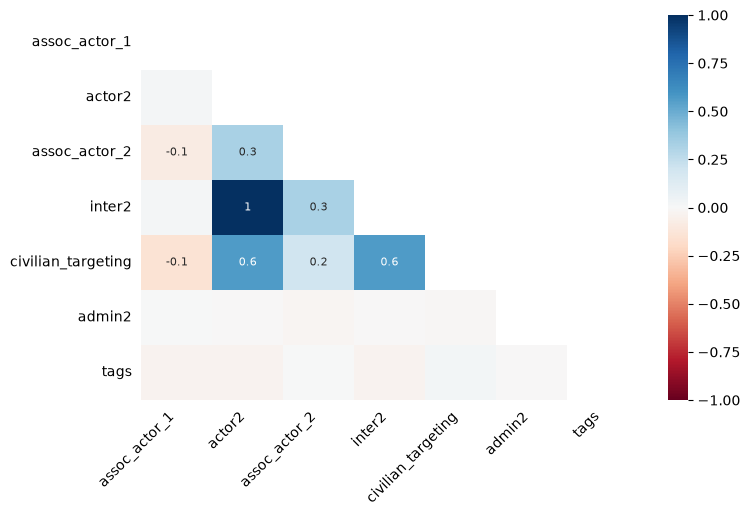

In [19]:
msno.heatmap(gaza_before, figsize=(8, 5), fontsize=10)
plt.show()

The heatmap shows a perfect positive missingness association between `actor2` and `inter2`. Both fields are blank in exactly the same records, which agrees with our structural-missingness checks. Positive values for other pairs show that their blanks tend to occur together, while negative values show that a blank in one field tends to accompany a recorded value in the other. The entirely blank `admin3` column is omitted because its missingness never varies. These correlations describe patterns in the export and cannot establish whether a field is MAR.

In [20]:
has_actor2 = gaza_before.loc[gaza_before.actor2.notna()]
assoc2_blank = has_actor2.assoc_actor_2.isna()
counts = pd.crosstab(has_actor2.event_type, assoc2_blank)
counts.columns = ["Recorded", "Blank"]
blank_pct = 100 * counts["Blank"] / counts.sum(axis=1)
display(counts.assign(Blank_pct=blank_pct.round(2)))

,Recorded,Blank,Blank_pct
event_type,,,
Battles,29,1619,98.24
Explosions/Remote violence,3169,9161,74.30
Protests,0,13,100.00
Riots,3,68,95.77
Strategic developments,1417,1730,54.97
Violence against civilians,200,614,75.43


We calculated the expected counts under the assumption that event type and the missingness of the second associated actor are independent. Each expected count equals its row total multiplied by its column total, divided by the overall total.


In [21]:
expected = pd.DataFrame(
    np.outer(counts.sum(axis=1), counts.sum(axis=0)) / counts.to_numpy().sum(),
    index=counts.index, columns=counts.columns,
)
display(expected.round(2))
print("Expected cells below 5:", (expected < 5).sum().sum())
print("Smallest expected count:", round(expected.min().min(), 2))

,Recorded,Blank
event_type,,
Battles,440.55,1207.45
Explosions/Remote violence,3296.12,9033.88
Protests,3.48,9.52
Riots,18.98,52.02
Strategic developments,841.27,2305.73
Violence against civilians,217.60,596.40


Expected cells below 5: 1
Smallest expected count: 3.48


For protests, there are 13 records with a listed second actor. Across all event types, 4,818 of 18,023 records have a recorded second associated actor. The expected count for the protest/Recorded cell is therefore **13 × 4,818 ÷ 18,023 = 3.48**, compared with an observed count of zero. This is the only expected cell below five among the 12 cells.

We used Monte Carlo resampling to estimate the chi-square p-value while retaining all six event types (Mugot, *EDA Bivariate Analysis of Categorical Variables*, 2026).

In [22]:
resampling = MonteCarloMethod(n_resamples=99_999, rng=np.random.default_rng(42))
result = chi2_contingency(counts.to_numpy(), correction=False, method=resampling)
cramers_v = np.sqrt(result.statistic / counts.to_numpy().sum())
print(f"Chi-square = {result.statistic:,.2f}, Monte Carlo p = {result.pvalue:.5f}")
print(f"Cramér’s V = {cramers_v:.3f}, smallest expected count = {result.expected_freq.min():.2f}")

Chi-square = 1,094.23, Monte Carlo p = 0.00001
Cramér’s V = 0.246, smallest expected count = 3.48


Among the 18,023 records with a listed second actor, `assoc_actor_2` is blank in **54.97%** of strategic developments and **98.24%** of battles. The chi-square statistic is **1,094.23** and Cramér’s V is **0.246**. None of the 99,999 simulated tables reached the observed statistic, so the reported **p = 0.00001** is the smallest value this run can report. We treat this as an exploratory association within the export because events may be related across time and place.

The differences show that these blanks vary with an observed field. That is consistent with MAR, but the test does not tell us whether unrecorded factors also affect the blanks. We kept our field-specific missingness decisions.

#### 2.2.5 Duplicates, Categories, Formats, and Data Types

We used the duplicate checks from profiling and checked the Gaza labels and formats before making type corrections.

In [23]:
label_fields = ["country", "admin1", "admin2", "disorder_type", "event_type",
                "sub_event_type", "actor1", "actor2", "civilian_targeting"]
category_audit = {}
for field in label_fields:
    labels = gaza_before[field].dropna()
    category_audit[field] = [labels.ne(labels.str.strip()).sum(),
                             labels.nunique() - labels.str.casefold().nunique()]
display(pd.DataFrame(category_audit, index=["Space variants", "Case variants"]).T)

,Space variants,Case variants
country,0,0
admin1,0,0
admin2,0,0
disorder_type,0,0
event_type,0,0
sub_event_type,0,0
actor1,0,0
actor2,0,0
civilian_targeting,0,0


In [24]:
def clean_gaza(events, parsed_dates):
    cleaned = events.drop(columns="admin3").copy()
    cleaned["event_date"] = parsed_dates
    precision = ["geo_precision", "time_precision"]
    assert cleaned[precision].isin([1, 2, 3]).all().all(), "Unexpected precision code."
    cleaned[precision] = cleaned[precision].astype(pd.CategoricalDtype([1, 2, 3], ordered=True))
    cleaned["district_missing"] = cleaned.admin2.isna()
    return cleaned

In [25]:
assert gaza_before.admin3.isna().all(), "Review admin3 before dropping it."
assert complete_cases["Core fields only"].all(), "Required analysis fields are missing."
master = clean_gaza(gaza_before, raw_dates.loc[scope])

In [26]:
assert master.event_date.notna().all(), "Some event dates could not be parsed."
assert master.event_date.dt.year.eq(master.year).all(), "Parsed dates disagree with the event years."
assert master.latitude.between(-90, 90).all(), "Latitude is outside its valid range."
assert master.longitude.between(-180, 180).all(), "Longitude is outside its valid range."
assert master.fatalities.ge(0).all(), "Reported fatalities are missing or negative."
assert master.admin1.eq("Gaza Strip").all(), "The working table includes an event outside Gaza."
print("Gaza event domain checks passed.")

Gaza event domain checks passed.


We removed the entirely empty `admin3` column. We parsed dates and converted geographic and date precision to ordered categories so the codes remain available for quality restrictions. We found no duplicate IDs, duplicate rows, or whitespace and case corrections to make. Similar actor names can represent different entities, so we kept the original labels for review.

### 2.3 Outlier Treatment

We compared the 1.5 × IQR upper fence with percentile screens. In the full export, the middle half of reported fatality counts is zero. In Gaza, the IQR fence is five. Both IQR fences would flag many valid events. We used the 99th percentile of the full export (23 reported fatalities) as a documented review threshold for this snapshot. In Gaza it flags 576 events (2.2%). The Gaza-only 99th percentile (39) would flag 262 events, and we show it as a comparison. The threshold is a descriptive aid for reviewing source records and stays outside the model inputs.

In [27]:
def fatality_limits(counts):
    q1, q3 = counts.quantile([0.25, 0.75])
    upper_fence = q3 + 1.5 * (q3 - q1)
    p99 = counts.quantile(0.99)
    return [q1, q3, upper_fence, counts.gt(upper_fence).sum(),
            p99, counts.gt(p99).sum(), counts.max()]

In [28]:
limit_columns = ["Q1", "Q3", "IQR upper fence", "Above fence", "P99", "Above P99", "Maximum"]
limits = [fatality_limits(raw.fatalities), fatality_limits(master.fatalities)]
display(pd.DataFrame(limits, index=["Full export", "Gaza"], columns=limit_columns))
severity_cutoff = raw.fatalities.quantile(0.99)
master["high_fatalities_review"] = master.fatalities.gt(severity_cutoff)

,Q1,Q3,IQR upper fence,Above fence,P99,Above P99,Maximum
Full export,0.0,0.0,0.0,9967,23.0,576,471
Gaza,0.0,2.0,5.0,3103,39.0,262,471


In [29]:
review_fields = ["event_id_cnty", "event_date", "location", "event_type", "fatalities", "source"]
display(master.nlargest(5, "fatalities")[review_fields])
print("Gaza records above the review threshold:", master.high_fatalities_review.sum())

,event_id_cnty,event_date,location,event_type,fatalities,source
17019,PSE37743,2023-10-17,Gaza - Az Zaytun,Explosions/Remote violence,471,Al-Ittihad; BBC News; CNN; France24; HRW; Isra...
18146,PSE39856,2023-10-28,Gaza - Nasr,Explosions/Remote violence,299,Palestinian Ministry of Health; Quds News Network
20143,PSE41414,2023-11-18,Jabalya Camp,Explosions/Remote violence,232,Al Ghad (Jordan); Ma'an News Agency; Newpress;...
22768,PSE44041,2023-12-26,Jabalya,Explosions/Remote violence,162,Newpress; Palestinian Ministry of Health; Quds...
19484,PSE40702,2023-11-10,Gaza - Ash Shati' Camp,Battles,150,Israeli Defense Forces; Ma'an News Agency; Qud...


Gaza records above the review threshold: 576


We flagged 576 Gaza events (2.2%) above 23 reported fatalities, the full-export 99th percentile, and kept their original totals. Those totals refer to the whole event. We kept the IDs and sources so the highest values can be checked against the event descriptions. Repeated coordinates can reflect a shared named location and are handled separately in the spatial table.

### 2.4 Data Integration

We used one ACLED snapshot, so there was no second source to merge. We used the download manifest to verify the file and read the observation dates. When building the weekly tables, we aligned event counts with a calendar and checked that the weekly keys were unique and the incident totals reconciled.

### 2.5 Transformation

| Fields | Our transformation | Reason |
| :--- | :--- | :--- |
| Event date | Calendar year and month for grouping, October 7 period, and Saturday-start week | Our descriptive and weekly comparisons use consistent date boundaries. |
| Targeting and disorder labels | Boolean flags, with an exact token check for political violence | Boolean flags can be counted. A record with several disorder labels can still qualify for the denominator. |
| Latitude and longitude | Degrees retained, radians added to the spatial table | Haversine distance uses radians. Standardizing the two axes independently would distort geographic distance. |
| Fatalities | Raw count retained, with a separate `log1p` field | The log version reduces the effect of the long tail in descriptive plots and keeps zero at zero. |
| Precision codes | Ordered categories and explicit quality flags | We use the codes for sensitivity checks and retain their original meaning. |
| Weekly counts, actor names and other labels | Counts in their original units and labels in their original form | The rolling count baseline uses interpretable units. We have no model input that requires one-hot encoding these labels or fitting a scaler in this phase. |

In [30]:
cutoff = pd.Timestamp("2023-10-07")
before_label = "Before Oct 7, 2023"
after_label = "Oct 7, 2023 onward"
coverage_start = pd.Timestamp(manifest["requested_filters"]["event_date_from"])
coverage_end = pd.Timestamp(manifest["requested_filters"]["event_date_to"])
post_oct7 = master.event_date.ge(cutoff)

In [31]:
assert master.event_date.between(coverage_start, coverage_end).all(), "Dates fall outside the download window."

In [32]:
master["period"] = np.where(post_oct7, after_label, before_label)
master["month_start"] = master.event_date.dt.to_period("M").dt.start_time
master["week_start"] = master.event_date.dt.to_period("W-FRI").dt.start_time
master["fatalities_log1p"] = np.log1p(master.fatalities)
master["targeting_flagged"] = master.civilian_targeting.eq("Civilian targeting").fillna(False)

In [33]:
# Match the whole token, including in records with multiple disorder labels.
disorder_tokens = master.disorder_type.fillna("").str.split(";")
master["political_violence"] = disorder_tokens.apply(
    lambda labels: "Political violence" in [label.strip() for label in labels])
display(master.groupby("disorder_type").political_violence.agg(["size", "sum"]))

,size,sum
disorder_type,,
Demonstrations,394,0
Political violence,22746,22746
Political violence; Demonstrations,7,7
Strategic developments,3517,0


### 2.6 Feature Engineering

We combined the targeting flag with the exact ACLED actor label `Civilians (Palestine)` in either actor field to identify focal events. The rule gives us a reproducible set of candidate records. We use the event notes when interpreting who did what. The share divides focal events by all recorded political-violence events from the same area and period.

In [34]:
civilian = "Civilians (Palestine)"
actor1_match = master.actor1.eq(civilian).fillna(False)
actor2_match = master.actor2.eq(civilian).fillna(False)
master["focal_event"] = master.targeting_flagged & (actor1_match | actor2_match)
print("Focal events outside political violence:", (master.focal_event & ~master.political_violence).sum())

Focal events outside political violence: 0


In [35]:
assert master.loc[master.focal_event, "political_violence"].all(), "Focal events fall outside the denominator."

In [36]:
master["geo_precision_1"] = master.geo_precision.eq(1)
master["time_precision_1"] = master.time_precision.eq(1)
master["coastal_location"] = master.location.str.startswith("Coast of ", na=False)
master["land_spatial_eligible"] = post_oct7 & master.focal_event & ~master.coastal_location

In [37]:
days = {before_label: (cutoff - coverage_start).days,
        after_label: (coverage_end - cutoff).days + 1}
period_summary = master.groupby("period")[["political_violence", "focal_event"]].sum()
period_summary["calendar_days"] = period_summary.index.map(days)
period_summary["focal_events_per_week"] = period_summary.focal_event * 7 / period_summary.calendar_days
period_summary["focal_share_pct"] = 100 * period_summary.focal_event / period_summary.political_violence
display(period_summary.round(2).T)

period,"Before Oct 7, 2023","Oct 7, 2023 onward"
political_violence,389.00,22364.00
focal_event,63.00,10651.00
calendar_days,644.00,725.00
focal_events_per_week,0.68,102.84
focal_share_pct,16.20,47.63


The two periods cover different numbers of days, so we show weekly rates alongside counts. The earlier period gives descriptive context. Our planned temporal model will compare weeks within the post–October 7 period.

#### 2.6.1 Weekly Features

We counted all recorded events, political-violence events, and focal events for each Gaza week and district-week. The Gaza-wide table retains records without a district. The district table uses known districts. Both tables retain weeks with zero recorded events. A focal share is undefined if no political violence was recorded. We mark the final partial week and require a complete week with recorded political violence for use in the historical reference. This rule avoids treating uncertain reporting coverage as evidence of inactivity.

In [38]:
post = master.loc[post_oct7]
known = post.loc[~post.district_missing]
calendar = pd.DataFrame({"week_start": pd.date_range(cutoff, coverage_end, freq="W-SAT")})
gaza = master[["admin1"]].drop_duplicates()
districts = master[["admin1", "admin2"]].dropna().drop_duplicates()

In [39]:
def count_events(events, keys):
    return events.groupby(keys, as_index=False).agg(
        recorded_events=("event_id_cnty", "size"),
        political_events=("political_violence", "sum"),
        focal_events=("focal_event", "sum"),
    )

In [40]:
def fill_calendar(counts, areas):
    keys = areas.columns.tolist() + ["week_start"]
    grid = areas.merge(calendar, how="cross")
    assert counts.set_index(keys).index.isin(grid.set_index(keys).index).all(), "Counts have unmatched week keys."
    weekly = grid.merge(counts, on=keys, how="left", validate="one_to_one")
    columns = ["recorded_events", "political_events", "focal_events"]
    weekly[columns] = weekly[columns].fillna(0).astype(int)
    return weekly.sort_values(keys).reset_index(drop=True)

In [41]:
gaza_counts = count_events(post, ["admin1", "week_start"])
district_counts = count_events(known, ["admin1", "admin2", "week_start"])
gaza_weekly = fill_calendar(gaza_counts, gaza)
district_weekly = fill_calendar(district_counts, districts)

In [42]:
for weekly in [gaza_weekly, district_weekly]:
    weekly["week_end"] = weekly.week_start + pd.Timedelta(days=6)
    weekly["complete_week"] = weekly.week_end.le(coverage_end)
    weekly["political_activity_recorded"] = weekly.political_events.gt(0)
    denominator = weekly.political_events.where(weekly.political_activity_recorded)
    weekly["focal_share"] = weekly.focal_events / denominator

In [43]:
for weekly in [gaza_weekly, district_weekly]:
    weekly["history_eligible"] = weekly.complete_week & weekly.political_activity_recorded
    weekly["focal_count_for_history"] = weekly.focal_events.where(weekly.history_eligible)

We used the preceding calendar week and the preceding four weeks as candidate history features. We shifted the counts before adding them up. If any of the four previous weeks is ineligible, the four-week feature remains missing. Current-week counts and shares describe the week being assessed and are available once that week has ended.

In [44]:
def add_lags(weekly, area):
    history = weekly.groupby(area)["focal_count_for_history"]
    weekly["previous_week_focal"] = history.shift(1)
    weekly["previous_four_weeks_focal"] = history.transform(
        lambda counts: counts.shift(1).rolling(4).sum())

In [45]:
add_lags(gaza_weekly, "admin1")
add_lags(district_weekly, "admin2")
print("Gaza complete weeks:", gaza_weekly.complete_week.sum())
print("Gaza weeks eligible for history:", gaza_weekly.history_eligible.sum())
display(district_weekly.groupby("admin2").history_eligible.agg(["size", "sum"])
        .set_axis(["Calendar weeks", "History-eligible weeks"], axis=1))

Gaza complete weeks: 103
Gaza weeks eligible for history: 103


,Calendar weeks,History-eligible weeks
admin2,,
Deir El Balah,104,103
Gaza City,104,103
Khan Yunis,104,103
North Gaza,104,101
Rafah,104,103


In [46]:
week_preview = ["week_start", "focal_events", "focal_share", "history_eligible",
                "previous_week_focal", "previous_four_weeks_focal"]
display(gaza_weekly[week_preview].head(6))
display(gaza_weekly.loc[~gaza_weekly.complete_week, week_preview])

,week_start,focal_events,focal_share,history_eligible,previous_week_focal,previous_four_weeks_focal
0,2023-10-07,139,0.594017,True,NaN,NaN
1,2023-10-14,159,0.729358,True,139.0,NaN
2,2023-10-21,203,0.702422,True,159.0,NaN
3,2023-10-28,254,0.705556,True,203.0,NaN
4,2023-11-04,233,0.638356,True,254.0,755.0
5,2023-11-11,134,0.412308,True,233.0,849.0


,week_start,focal_events,focal_share,history_eligible,previous_week_focal,previous_four_weeks_focal
103,2025-09-27,80,0.601504,False,131.0,554.0


### 2.7 Data Reduction

We retained all 26,664 Gaza-coded events in the clean master, including coastal events. For land-based clustering we kept post–October 7 focal events and excluded records with a location label starting with “Coast of”. This reproducible label rule identifies coast-coded locations and does not require a coastline boundary or a guess about an incident’s coordinates. It removes 68 of 10,651 post–October 7 focal records from the land-based clustering file. The weekly tables still represent all Gaza-coded locations.

We retained the 10,583 spatial incidents across 101 distinct coordinate pairs. Many events share a recorded location, so we will interpret clusters as concentrations of recorded incidents around those locations. The main spatial input uses only latitude and longitude in radians. We kept the source fields and event IDs with the coordinates to support source review and a higher-precision sensitivity run.

In [47]:
post_focal = post.loc[post.focal_event]
incidents = master.loc[master.land_spatial_eligible].copy()
incidents["latitude_rad"] = np.radians(incidents.latitude)
incidents["longitude_rad"] = np.radians(incidents.longitude)
print("Post–October 7 focal events, all Gaza:", len(post_focal))
print("Coast-coded focal events excluded from clustering:", post_focal.coastal_location.sum())
print("Land-based focal incidents:", len(incidents))

Post–October 7 focal events, all Gaza: 10651
Coast-coded focal events excluded from clustering: 68
Land-based focal incidents: 10583


In [48]:
coordinates = ["latitude", "longitude"]
print("Distinct coordinate pairs:", len(incidents[coordinates].drop_duplicates()))
print("Rows repeating a prior coordinate pair:", incidents.duplicated(coordinates).sum())
print("Geographic precision code 1:", incidents.geo_precision_1.sum())
display(incidents.groupby("geo_precision", observed=False).size().rename("Spatial incidents"))

Distinct coordinate pairs: 101
Rows repeating a prior coordinate pair: 10482
Geographic precision code 1: 7576


geo_precision
1    7576
2    2976
3      31
Name: Spatial incidents, dtype: int64

### 2.8 Save Outputs

We documented the decisions and checked their impact before writing the cleaned tables.

#### 2.8.1 Preprocessing Log

| Issue and evidence | Action | Reason |
| :--- | :--- | :--- |
| The export includes 32,151 West Bank and 27 separately coded maritime events | We selected Gaza-coded rows for the master. | Gaza is our agreed study area. |
| `admin3` is empty in every source record | We dropped the field from the working copy. | It provides no usable location detail. |
| `actor2` and `inter2` are both blank in 8,641 Gaza records with single-sided interaction coding | We kept the blank values and their records. | Filling an actor would invent a second participant. |
| Associated actor fields and tags have blanks | We preserved the source values. | We cannot reconstruct optional information from a blank. |
| 15,932 Gaza records have no civilian-targeting flag | We retained the source field and derived a boolean for recorded targeting. | This distinguishes the presence and absence of the recorded flag. |
| Four Gaza events have no district | We flagged them and kept them in Gaza-wide totals. We omitted them from district totals. | Their coast location does not identify a district. |
| No selected placeholders, exact duplicates, repeated IDs, or whitespace and case variants were found | We kept the records and original labels. | These checks provided no basis for deleting rows or harmonizing labels. |
| Text dates and integer precision codes | We parsed dates and converted the two precision fields to ordered categories. | The types support date grouping and precision checks. |
| Reported fatalities reach 471 and the full-export IQR is zero | We flagged counts above 23 for review and kept the original totals. | The full-export 99th percentile flags 2.2% of Gaza events for source review without removing any. |
| Coast-coded locations and repeated coordinates affect spatial interpretation | We excluded coast-coded focal records from the land analysis and counted distinct coordinate pairs. | Clustering should represent recorded land locations and the precision of the source. |
| Unequal descriptive periods and uncertain weekly coverage | We calculated rates and shares with matching denominators, marked incomplete weeks, and shifted history features. | This keeps the comparisons interpretable and the historical inputs chronological. |

#### 2.8.2 Before-and-After Data Quality Report

We show the full raw export, the Gaza subset before cleaning, and the cleaned Gaza master. The Gaza-before column separates the effect of filtering from the effect of cleaning. We compare missingness across all fields and across the same retained source fields. Dropping an empty field and adding features changes the first percentage without filling the remaining blanks.

In [49]:
stages = {"Full raw": raw, "Gaza before": gaza_before, "Gaza cleaned": master}
source_fields = raw.columns.drop("admin3")
quality = pd.DataFrame()
for label, frame in stages.items():
    quality.loc["Rows", label] = len(frame)
    quality.loc["Columns", label] = frame.shape[1]
    quality.loc["Missing cells (%) · all fields", label] = frame.isnull().to_numpy().mean() * 100
    quality.loc["Missing cells (%) · retained source fields", label] = frame[source_fields].isnull().to_numpy().mean() * 100

In [50]:
for label, frame in stages.items():
    quality.loc["Exact duplicate rows", label] = frame.duplicated().sum()
    quality.loc["Repeated event IDs", label] = frame.event_id_cnty.duplicated().sum()
    quality.loc["Rows above fatality review threshold", label] = frame.fatalities.gt(severity_cutoff).sum()
quality.loc["Outlier flags applied"] = [0, 0, master.high_fatalities_review.sum()]
quality.loc["Inconsistent categories fixed"] = [0, 0, 0]
quality.loc["Source types corrected"] = [0, 0, 3]
display(quality.round(2))

,Full raw,Gaza before,Gaza cleaned
Rows,58842.00,26664.00,26664.00
Columns,31.00,31.00,43.00
Missing cells (%) · all fields,12.11,13.05,7.08
Missing cells (%) · retained source fields,9.18,10.15,10.15
Exact duplicate rows,0.00,0.00,0.00
Repeated event IDs,0.00,0.00,0.00
Rows above fatality review threshold,576.00,576.00,576.00
Outlier flags applied,0.00,0.00,576.00
Inconsistent categories fixed,0.00,0.00,0.00
Source types corrected,0.00,0.00,3.00


In [51]:
compare_fields = ["Type", "Missing", "Missing (%)"]
clean_profile = profile(master)
field_report = pd.concat([gaza_profile[compare_fields], clean_profile[compare_fields]],
                         keys=["Gaza before", "Gaza cleaned"], axis=1)
display(field_report)

Gaza before                         Gaza cleaned  \
                              Type  Missing Missing (%)            Type   
event_id_cnty                  str      0.0        0.00             str   
event_date                     str      0.0        0.00  datetime64[us]   
year                         int64      0.0        0.00           int64   
time_precision               int64      0.0        0.00        category   
disorder_type                  str      0.0        0.00             str   
event_type                     str      0.0        0.00             str   
sub_event_type                 str      0.0        0.00             str   
actor1                         str      0.0        0.00             str   
assoc_actor_1                  str  25789.0       96.72             str   
inter1                         str      0.0        0.00             str   
actor2                         str   8641.0       32.41             str   
assoc_actor_2                  str  21846.0       81.93             str   
inter2                         str   8641.0       32.41             str   
interaction                    str      0.0        0.00             str   
civilian_targeting             str  15932.0       59.75             str   
iso                          int64      0.0        0.00           int64   
region                         str      0.0        0.00             str   
country                        str      0.0        0.00             str   
admin1                         str      0.0        0.00             str   
admin2                         str      4.0        0.02             str   
admin3                     float64  26664.0      100.00             NaN   
location                       str      0.0        0.00             str   
latitude                   float64      0.0        0.00         float64   
longitude                  float64      0.0        0.00         float64   
geo_precision                int64      0.0        0.00        category   
source                         str      0.0        0.00             str   
source_scale                   str      0.0        0.00             str   
notes                          str      0.0        0.00             str   
fatalities                   int64      0.0        0.00           int64   
tags                           str    333.0        1.25             str   
timestamp                    int64      0.0        0.00           int64   
district_missing               NaN      NaN         NaN            bool   
high_fatalities_review         NaN      NaN         NaN            bool   
period                         NaN      NaN         NaN             str   
month_start                    NaN      NaN         NaN  datetime64[us]   
week_start                     NaN      NaN         NaN  datetime64[us]   
fatalities_log1p               NaN      NaN         NaN         float64   
targeting_flagged              NaN      NaN         NaN            bool   
political_violence             NaN      NaN         NaN            bool   
focal_event                    NaN      NaN         NaN            bool   
geo_precision_1                NaN      NaN         NaN            bool   
time_precision_1               NaN      NaN         NaN            bool   
coastal_location               NaN      NaN         NaN            bool   
land_spatial_eligible          NaN      NaN         NaN            bool   

                                             
                        Missing Missing (%)  
event_id_cnty               0.0        0.00  
event_date                  0.0        0.00  
year                        0.0        0.00  
time_precision              0.0        0.00  
disorder_type               0.0        0.00  
event_type                  0.0        0.00  
sub_event_type              0.0        0.00  
actor1                      0.0        0.00  
assoc_actor_1           25789.0       96.72  
inter1                      0.0        0.00  
actor2              

We corrected three source types. The event date changed from text to a datetime, and the two precision fields changed from integers to ordered categories. No Gaza records were deleted from the master during cleaning. The district and spatial restrictions apply only to the respective analysis tables.

#### 2.8.3 Export Checks and Saved Files

We checked the weekly tables against the incident counts before saving. We also checked that the spatial exclusions reconcile with the coastal count and that the raw file still matches its documented hash.

In [52]:
def validate_weekly(weekly, keys, expected_rows, events):
    assert len(weekly) == expected_rows, "Unexpected number of calendar rows."
    assert not weekly.duplicated(keys).any(), "Duplicate weekly keys."
    assert weekly.recorded_events.sum() == len(events), "Recorded event counts do not reconcile."
    assert weekly.political_events.sum() == events.political_violence.sum(), "Political counts do not reconcile."
    assert weekly.focal_events.sum() == events.focal_event.sum(), "Focal event counts do not reconcile."
    assert weekly.focal_events.le(weekly.political_events).all(), "Focal counts exceed political counts."
    assert weekly.political_events.le(weekly.recorded_events).all(), "Political counts exceed recorded counts."

In [53]:
gaza_keys = ["admin1", "week_start"]
district_keys = ["admin1", "admin2", "week_start"]
validate_weekly(gaza_weekly, gaza_keys, len(calendar), post)
validate_weekly(district_weekly, district_keys, len(districts) * len(calendar), known)
print("Gaza and district weekly keys, row counts, and event totals reconcile.")

Gaza and district weekly keys, row counts, and event totals reconcile.


In [54]:
assert master.event_id_cnty.equals(gaza_before.event_id_cnty), "Gaza event IDs changed during cleaning."
expected_spatial = post_focal.loc[~post_focal.coastal_location, "event_id_cnty"]
assert incidents.event_id_cnty.equals(expected_spatial), "Spatial event IDs do not reconcile."
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_hash, "The raw file changed."
print("Gaza and spatial event IDs reconcile. The raw file is unchanged.")

Gaza and spatial event IDs reconcile. The raw file is unchanged.


In [55]:
out_dir = root / "data/processed"
out_dir.mkdir(parents=True, exist_ok=True)
outputs = {"acled_events_clean.csv": master, "acled_focal_incidents.csv": incidents,
           "acled_gaza_week.csv": gaza_weekly, "acled_district_week.csv": district_weekly}
for filename, frame in outputs.items():
    frame.to_csv(out_dir / filename, index=False)
    print(filename, frame.shape)

acled_events_clean.csv (26664, 43)
acled_focal_incidents.csv (10583, 45)
acled_gaza_week.csv (104, 13)
acled_district_week.csv (520, 14)


| File in `data/processed` | Role in the next phases |
| :--- | :--- |
| `acled_events_clean.csv` | Gaza master for descriptive, actor, and coverage analyses across both periods |
| `acled_focal_incidents.csv` | Post–October 7 land-based focal incidents for DBSCAN and precision checks |
| `acled_gaza_week.csv` | Gaza-wide post–October 7 weekly counts and earlier-week features |
| `acled_district_week.csv` | District-week counts and earlier-week features for finer comparisons |

We will use the cleaned master for Phase 3 exploration and the incident and weekly tables for Phase 4. Our Phase 4 temporal split will be chronological, and any fitted transformations will use the training period. CSV preserves the values, so we will parse the dates and restore precision categories when reloading the data.

### 2.9 References

- Group 7, *Phase 1 · Dataset Selection and Business Problem*.
- *DS312 Final Project Guide*, Section 4.
- *Bautro Lab 2*, preprocessing workflow reference.
- Mugot, C. J. S. *EDA Bivariate Analysis of Categorical Variables*, 2026.
- ACLED, Palestine event-level export and download manifest. [ACLED codebook](https://acleddata.com/methodology/acled-codebook)